# Knee Osteoarthritis Severity Diagnosis - PS22
### Kishore Kanna K | RA2311026050129 | AIML-A

## Cell 1 — Install Dependencies

In [1]:
!pip install timm scikit-learn tqdm -q

## Cell 2 — Imports

In [2]:
import os
import random
import warnings
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from pathlib import Path
from PIL import Image
from collections import Counter
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as transforms
import torchvision.models as tv_models
import timm

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc as sk_auc
)
from sklearn.preprocessing import label_binarize
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
print(f'timm   : {timm.__version__}')
if torch.cuda.is_available():
    print(f'GPU    : {torch.cuda.get_device_name(0)}')

Device : cuda
timm   : 1.0.24
GPU    : Tesla T4


## Cell 3 — Configuration

In [3]:
# ── Paths ─────────────────────────────────────────────────────────────────────
DATA_ROOT = Path('/kaggle/input/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity')
TRAIN_DIR = DATA_ROOT / 'train'
VAL_DIR   = DATA_ROOT / 'val'
TEST_DIR  = DATA_ROOT / 'test'
SAVE_DIR  = Path('/kaggle/working')

# ── Dataset ───────────────────────────────────────────────────────────────────
NUM_CLASSES = 5
IMG_SIZE    = 224
CLASS_NAMES = [
    'Grade0_Normal',
    'Grade1_Doubtful',
    'Grade2_Minimal',
    'Grade3_Moderate',
    'Grade4_Severe'
]

# ── Training (same as paper) ──────────────────────────────────────────────────
BATCH_SIZE   = 16     # paper used 16
EPOCHS       = 30     # max epochs (early stopping may end it sooner)
LR           = 1e-4   # same as paper
WEIGHT_DECAY = 0.01   # same as paper (AdamW)

# ── Early Stopping ────────────────────────────────────────────────────────────
ES_PATIENCE  = 7      # stop if no improvement for 7 epochs
ES_MIN_DELTA = 0.001  # minimum improvement to count

# ── ImageNet normalisation ────────────────────────────────────────────────────
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# Verify paths exist
print('Checking dataset paths...')
for d in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    status = 'OK' if d.exists() else 'NOT FOUND — check dataset is added'
    print(f'  [{status}] {d}')

Checking dataset paths...
  [OK] /kaggle/input/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/train
  [OK] /kaggle/input/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/val
  [OK] /kaggle/input/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/test


## Cell 4 — Preprocessing
Replicates the paper pipeline and adds **CLAHE** (Improvement #6)

In [4]:
def preprocess_xray(img_np):
    """
    Paper pipeline:
      1. Laplacian sharpening
      2. High-pass filter
      3. Gaussian smoothing (approx. Kalman)

    Improvement #6 — CLAHE:
      Contrast Limited Adaptive Histogram Equalisation.
      Enhances local contrast in X-ray joint-space regions
      without over-brightening bone or background areas.
      Specifically helps distinguish Grade 2/3/4 where
      joint space narrowing is the key visual feature.
    """
    # Convert to grayscale
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)

    # 1. Laplacian sharpening (paper)
    lap       = cv2.Laplacian(gray, cv2.CV_64F)
    sharpened = np.clip(
        gray.astype(np.float64) - 0.5 * lap, 0, 255
    ).astype(np.uint8)

    # 2. High-pass filter (paper)
    hp_kernel = np.array([
        [-1, -1, -1],
        [-1,  9, -1],
        [-1, -1, -1]
    ])
    hp = np.clip(
        cv2.filter2D(sharpened, -1, hp_kernel), 0, 255
    ).astype(np.uint8)

    # 3. Gaussian smoothing (paper — approximates Kalman filter)
    smoothed = cv2.GaussianBlur(hp, (3, 3), 0)

    # 4. CLAHE — IMPROVEMENT #6
    #    clipLimit=2.0  : prevents over-amplifying noise
    #    tileGridSize   : applies equalisation in 8x8 local tiles
    clahe    = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(smoothed)

    # Convert back to 3-channel RGB for model input
    return cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB)


class PreprocessTransform:
    """Wraps preprocess_xray so it works inside transforms.Compose."""
    def __call__(self, img):
        img_np    = np.array(img.convert('RGB'))
        processed = preprocess_xray(img_np)
        return Image.fromarray(processed)


# ── Transforms ────────────────────────────────────────────────────────────────
# Augmentation: same as paper (rotation, zoom, horizontal flip)
train_transform = transforms.Compose([
    PreprocessTransform(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.RandomAffine(degrees=0, scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

val_transform = transforms.Compose([
    PreprocessTransform(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

print('Preprocessing pipeline ready.')
print('  Paper steps : Laplacian sharpen + High-pass filter + Gaussian smooth')
print('  Added (ours): CLAHE contrast enhancement')

Preprocessing pipeline ready.
  Paper steps : Laplacian sharpen + High-pass filter + Gaussian smooth
  Added (ours): CLAHE contrast enhancement


## Cell 5 — Dataset & DataLoaders
Includes **WeightedRandomSampler** (Improvement #2)

In [5]:
class KneeOADataset(Dataset):
    """
    Expects folder structure:
        split/
          0/  ← Grade 0 images
          1/  ← Grade 1 images
          2/  ← Grade 2 images
          3/  ← Grade 3 images
          4/  ← Grade 4 images
    """
    def __init__(self, root_dir, transform=None):
        self.root      = Path(root_dir)
        self.transform = transform
        self.samples   = []
        self.labels    = []

        folders = sorted([f for f in self.root.iterdir() if f.is_dir()])
        for label_idx, folder in enumerate(folders):
            for ext in ['*.png', '*.jpg', '*.jpeg', '*.PNG', '*.JPG']:
                for img_path in folder.glob(ext):
                    self.samples.append(img_path)
                    self.labels.append(label_idx)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img = Image.open(self.samples[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]


print('Loading datasets...')
train_dataset = KneeOADataset(TRAIN_DIR, transform=train_transform)
val_dataset   = KneeOADataset(VAL_DIR,   transform=val_transform)
test_dataset  = KneeOADataset(TEST_DIR,  transform=val_transform)

# Print distribution
for name, ds in [('Train', train_dataset), ('Val', val_dataset), ('Test', test_dataset)]:
    dist = Counter(ds.labels)
    print(f'\n  {name} set — {len(ds)} images')
    for i in range(NUM_CLASSES):
        print(f'    Grade {i}: {dist.get(i, 0)}')

# ── Improvement #2 — WeightedRandomSampler ────────────────────────────────────
# Problem: Grade 4 has 251 images vs Grade 0's 3253.
# Without this, the model barely learns Grade 3 and 4.
# Solution: compute a weight per sample so rare classes are
# sampled more frequently during training.
class_counts   = Counter(train_dataset.labels)
total_samples  = len(train_dataset)
class_weights  = {
    cls: total_samples / (NUM_CLASSES * count)
    for cls, count in class_counts.items()
}
sample_weights = [class_weights[lbl] for lbl in train_dataset.labels]
sampler = WeightedRandomSampler(
    weights     = sample_weights,
    num_samples = len(sample_weights),
    replacement = True
)

print('\nClass weights for sampler:')
for cls, w in class_weights.items():
    print(f'  Grade {cls}: {w:.4f}')

# Note: sampler replaces shuffle=True for train_loader
train_loader = DataLoader(
    train_dataset,
    batch_size  = BATCH_SIZE,
    sampler     = sampler,
    num_workers = 2,
    pin_memory  = True
)
val_loader = DataLoader(
    val_dataset,
    batch_size  = BATCH_SIZE,
    shuffle     = False,
    num_workers = 2,
    pin_memory  = True
)
test_loader = DataLoader(
    test_dataset,
    batch_size  = BATCH_SIZE,
    shuffle     = False,
    num_workers = 2,
    pin_memory  = True
)

print(f'\nTrain batches : {len(train_loader)}')
print(f'Val   batches : {len(val_loader)}')
print(f'Test  batches : {len(test_loader)}')

Loading datasets...

  Train set — 5778 images
    Grade 0: 2286
    Grade 1: 1046
    Grade 2: 1516
    Grade 3: 757
    Grade 4: 173

  Val set — 826 images
    Grade 0: 328
    Grade 1: 153
    Grade 2: 212
    Grade 3: 106
    Grade 4: 27

  Test set — 1656 images
    Grade 0: 639
    Grade 1: 296
    Grade 2: 447
    Grade 3: 223
    Grade 4: 51

Class weights for sampler:
  Grade 0: 0.5055
  Grade 1: 1.1048
  Grade 2: 0.7623
  Grade 3: 1.5266
  Grade 4: 6.6798

Train batches : 362
Val   batches : 52
Test  batches : 104


## Cell 6 — Visualise Samples & Class Distribution

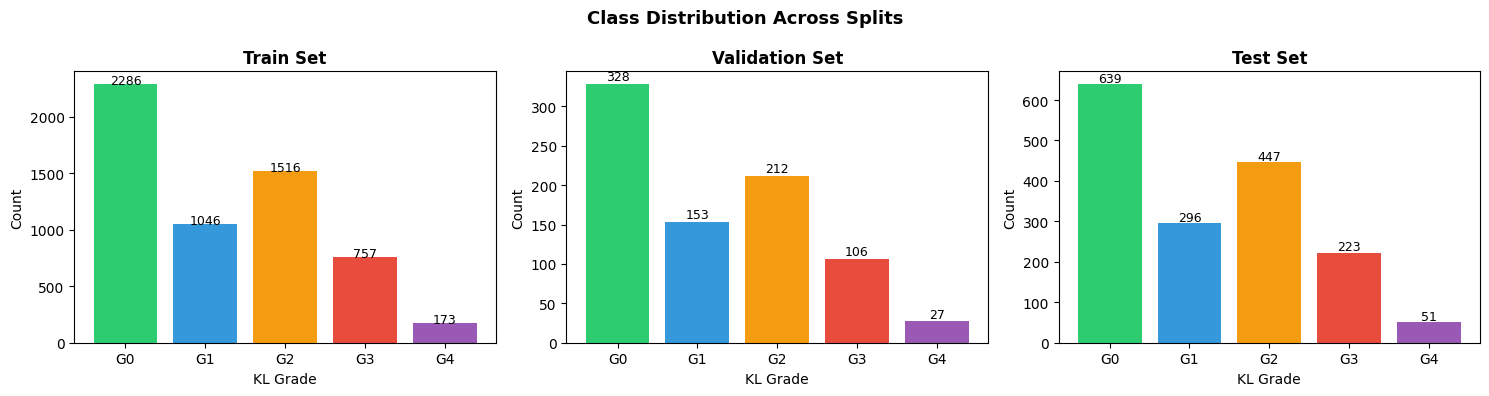

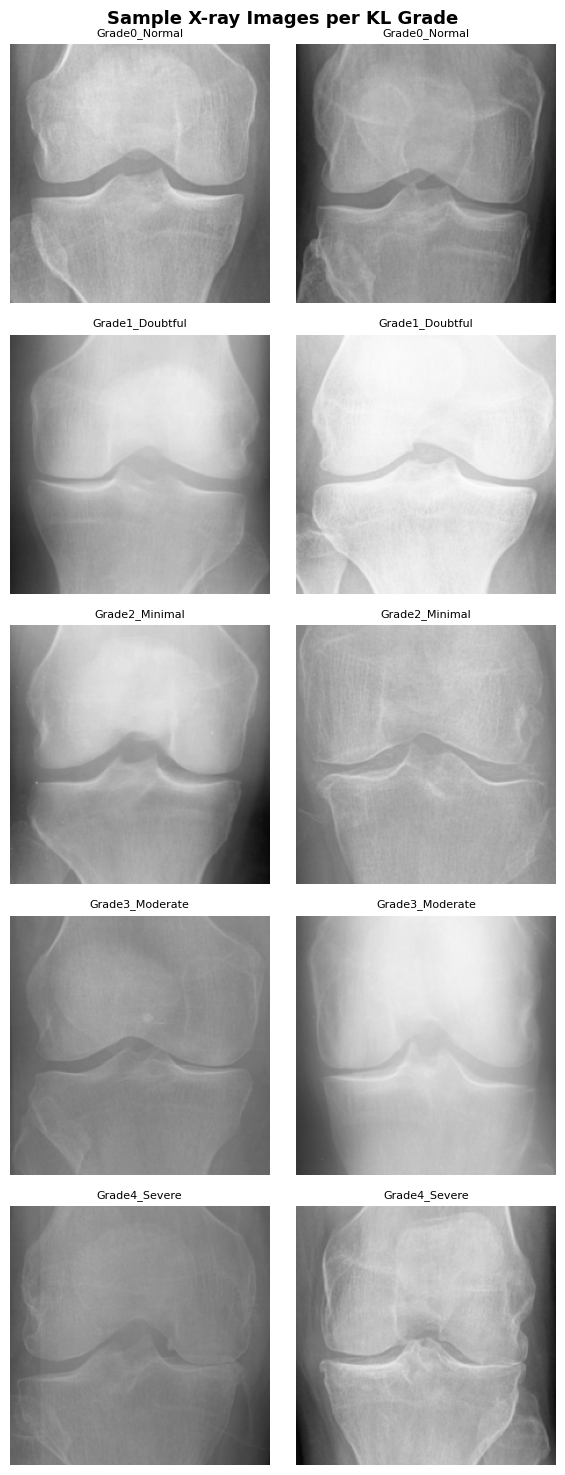

In [6]:
def plot_class_distribution():
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    colors = ['#2ecc71', '#3498db', '#f39c12', '#e74c3c', '#9b59b6']
    for ax, (dataset, title) in zip(axes, [
        (train_dataset, 'Train'),
        (val_dataset,   'Validation'),
        (test_dataset,  'Test')
    ]):
        dist   = Counter(dataset.labels)
        values = [dist.get(i, 0) for i in range(NUM_CLASSES)]
        bars   = ax.bar([f'G{i}' for i in range(NUM_CLASSES)], values, color=colors)
        for bar, val in zip(bars, values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 5,
                str(val), ha='center', fontsize=9
            )
        ax.set_title(f'{title} Set', fontweight='bold')
        ax.set_ylabel('Count')
        ax.set_xlabel('KL Grade')
    plt.suptitle('Class Distribution Across Splits', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(SAVE_DIR / 'class_distribution.png', dpi=150, bbox_inches='tight')
    plt.show()


def show_sample_images(n_per_class=2):
    fig, axes = plt.subplots(
        NUM_CLASSES, n_per_class,
        figsize=(n_per_class * 3, NUM_CLASSES * 3)
    )
    for grade in range(NUM_CLASSES):
        indices = [i for i, l in enumerate(train_dataset.labels) if l == grade]
        chosen  = random.sample(indices, min(n_per_class, len(indices)))
        for col, idx in enumerate(chosen):
            img = Image.open(train_dataset.samples[idx]).convert('RGB')
            axes[grade][col].imshow(img, cmap='gray')
            axes[grade][col].set_title(CLASS_NAMES[grade], fontsize=8)
            axes[grade][col].axis('off')
    plt.suptitle('Sample X-ray Images per KL Grade', fontweight='bold', fontsize=13)
    plt.tight_layout()
    plt.savefig(SAVE_DIR / 'sample_images.png', dpi=150, bbox_inches='tight')
    plt.show()


plot_class_distribution()
show_sample_images()

## Cell 7 — Loss Function & Early Stopping
Uses **standard CrossEntropy** (same as paper) + **Early Stopping** (Improvement #8)

In [7]:
# ── Loss — Standard CrossEntropy (same as paper) ──────────────────────────────
criterion = nn.CrossEntropyLoss()
print('Loss function: CrossEntropyLoss (same as paper)')


# ── Improvement #8 — Early Stopping ──────────────────────────────────────────
# Paper trained a fixed 30 epochs. We stop when val accuracy
# does not improve for ES_PATIENCE consecutive epochs.
# This avoids overfitting and saves training time.

class EarlyStopping:
    def __init__(self, patience=ES_PATIENCE, min_delta=ES_MIN_DELTA):
        self.patience    = patience
        self.min_delta   = min_delta
        self.counter     = 0
        self.best_acc    = 0.0
        self.should_stop = False

    def __call__(self, val_acc):
        if val_acc > self.best_acc + self.min_delta:
            self.best_acc = val_acc
            self.counter  = 0
        else:
            self.counter += 1
            print(f'    [EarlyStopping] No improvement '
                  f'{self.counter}/{self.patience}')
            if self.counter >= self.patience:
                self.should_stop = True

    def reset(self):
        self.counter     = 0
        self.best_acc    = 0.0
        self.should_stop = False


print(f'Early Stopping: patience={ES_PATIENCE}, min_delta={ES_MIN_DELTA}')

Loss function: CrossEntropyLoss (same as paper)
Early Stopping: patience=7, min_delta=0.001


## Cell 8 — Model Builders

In [8]:
def build_vgg19(num_classes=NUM_CLASSES):
    """VGG19 pretrained on ImageNet. Replace final layer for 5-class output."""
    model = tv_models.vgg19(weights='DEFAULT')
    model.classifier[6] = nn.Linear(4096, num_classes)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f'  Built VGG19 | Params: {n_params:.1f}M | All layers unfrozen')
    return model


def build_vit(model_name, num_classes=NUM_CLASSES):
    """
    Build a Vision Transformer from timm.
    All pretrained on ImageNet, all layers unfrozen (same approach as paper).

    GCViT  — from the paper
    MaxViT — from the paper
    SwinB  — Improvement #10 (stronger hierarchical ViT)
    """
    timm_names = {
        'GCViT' : 'gcvit_base',
        'MaxViT': 'maxvit_base_tf_224',
        'SwinB' : 'swin_base_patch4_window7_224',
    }
    assert model_name in timm_names, \
        f"Unknown model '{model_name}'. Choose from {list(timm_names.keys())}"

    model    = timm.create_model(
        timm_names[model_name],
        pretrained   = True,
        num_classes  = num_classes
    )
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f'  Built {model_name} | Params: {n_params:.1f}M | All layers unfrozen')
    return model


print('Model builders ready.')
print('Available ViTs: GCViT (paper), MaxViT (paper), SwinB (improvement)')

Model builders ready.
Available ViTs: GCViT (paper), MaxViT (paper), SwinB (improvement)


## Cell 9 — Evaluation Utilities

In [9]:
@torch.no_grad()
def evaluate(model, loader, desc='Evaluating'):
    """Run model on loader, return metrics dict."""
    model.eval()
    loss_sum = 0.0
    correct  = 0
    total    = 0
    all_preds, all_probs, all_labels = [], [], []

    pbar = tqdm(loader, desc=f'  {desc}', leave=False, ncols=80)
    for imgs, labels in pbar:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        outputs = model(imgs)
        probs   = F.softmax(outputs, dim=1)
        loss    = criterion(outputs, labels)

        loss_sum += loss.item() * imgs.size(0)
        preds     = outputs.argmax(dim=1)
        correct  += (preds == labels).sum().item()
        total    += labels.size(0)

        all_preds.append(preds.cpu())
        all_probs.append(probs.cpu())
        all_labels.append(labels.cpu())

    all_preds  = torch.cat(all_preds).numpy()
    all_probs  = torch.cat(all_probs).numpy()
    all_labels = torch.cat(all_labels).numpy()

    y_bin = label_binarize(all_labels, classes=list(range(NUM_CLASSES)))
    try:
        auc_score = roc_auc_score(
            y_bin, all_probs, multi_class='ovr', average='macro'
        )
    except ValueError:
        auc_score = 0.0

    return {
        'loss'  : loss_sum / total,
        'acc'   : correct / total,
        'preds' : all_preds,
        'probs' : all_probs,
        'labels': all_labels,
        'auc'   : auc_score,
    }


def print_metrics(results, model_name=''):
    """Print full metrics table matching the paper's Table III format."""
    rep   = classification_report(
        results['labels'], results['preds'],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )
    macro = rep['macro avg']
    print(f'\n  ── {model_name} Test Metrics (Paper Format) ──')
    print(f'  Accuracy  : {results["acc"]*100:.2f}%')
    print(f'  Precision : {macro["precision"]:.4f}')
    print(f'  Recall    : {macro["recall"]:.4f}')
    print(f'  F1-Score  : {macro["f1-score"]:.4f}')
    print(f'  AUC       : {results["auc"]:.4f}')
    print()
    print(classification_report(
        results['labels'], results['preds'],
        target_names=CLASS_NAMES,
        zero_division=0
    ))
    return macro


def plot_confusion_matrix(results, model_name):
    cm      = confusion_matrix(results['labels'], results['preds'])
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, data, fmt, title in zip(
        axes,
        [cm, cm_norm],
        ['d', '.2f'],
        ['Raw Counts', 'Normalised']
    ):
        sns.heatmap(
            data, annot=True, fmt=fmt, cmap='Blues', ax=ax,
            xticklabels=[f'G{i}' for i in range(NUM_CLASSES)],
            yticklabels=[f'G{i}' for i in range(NUM_CLASSES)]
        )
        ax.set_title(f'{model_name} — {title}', fontweight='bold')
        ax.set_ylabel('True')
        ax.set_xlabel('Predicted')
    plt.tight_layout()
    plt.savefig(SAVE_DIR / f'cm_{model_name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def plot_roc_curves(results, model_name):
    y_bin  = label_binarize(results['labels'], classes=list(range(NUM_CLASSES)))
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']

    plt.figure(figsize=(7, 6))
    for i in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], results['probs'][:, i])
        roc_auc     = sk_auc(fpr, tpr)
        plt.plot(fpr, tpr, color=colors[i], lw=2,
                 label=f'Grade {i} (AUC={roc_auc:.3f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=1)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Per-Class ROC Curves — {model_name}', fontweight='bold')
    plt.legend(loc='lower right', fontsize=9)
    plt.tight_layout()
    plt.savefig(SAVE_DIR / f'roc_{model_name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def plot_training_history(history, model_name):
    epochs = range(1, len(history['tr_loss']) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(epochs, history['tr_loss'], label='Train', color='#3498db')
    axes[0].plot(epochs, history['va_loss'], label='Val',   color='#e74c3c')
    axes[0].set_title('Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()

    axes[1].plot(epochs, [a * 100 for a in history['tr_acc']],
                 label='Train', color='#3498db')
    axes[1].plot(epochs, [a * 100 for a in history['va_acc']],
                 label='Val',   color='#e74c3c')
    axes[1].axhline(66.14, color='gray', linestyle='--',
                    linewidth=1.2, label='Paper best (66.14%)')
    axes[1].set_title('Accuracy (%)')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()

    axes[2].plot(epochs, history['va_auc'], color='#9b59b6', label='Val AUC')
    axes[2].axhline(0.860, color='gray', linestyle='--',
                    linewidth=1.2, label='Paper best AUC (0.860)')
    axes[2].set_title('AUC (Validation)')
    axes[2].set_xlabel('Epoch')
    axes[2].legend()

    plt.suptitle(f'Training History — {model_name}', fontweight='bold', fontsize=13)
    plt.tight_layout()
    plt.savefig(SAVE_DIR / f'history_{model_name}.png', dpi=150, bbox_inches='tight')
    plt.show()


print('Evaluation utilities ready.')

Evaluation utilities ready.


## Cell 10 — Training Loop

In [10]:
def train_model(model, model_name):
    """
    Train a model using:
    - AdamW optimizer (same as paper)
    - Fixed LR 1e-4 (same as paper)
    - Standard CrossEntropy loss (same as paper)
    - All layers unfrozen (same as paper)
    - WeightedRandomSampler already applied in train_loader (improvement #2)
    - Early Stopping with patience=7 (improvement #8)
    - tqdm progress bars per epoch
    """
    model     = model.to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr           = LR,
        weight_decay = WEIGHT_DECAY
    )

    history = {
        'tr_loss': [], 'tr_acc': [],
        'va_loss': [], 'va_acc': [], 'va_auc': []
    }
    best_val_acc = 0.0
    best_weights = None
    early_stop   = EarlyStopping()

    print(f'\n{"="*65}')
    print(f'  Training : {model_name}')
    print(f'  Epochs   : up to {EPOCHS} (early stop patience={ES_PATIENCE})')
    print(f'  LR       : {LR}  |  Batch: {BATCH_SIZE}  |  Optimizer: AdamW')
    print(f'{"="*65}')

    total_start = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        tr_loss  = 0.0
        correct  = 0
        total    = 0
        ep_start = time.time()

        # tqdm bar for each epoch
        pbar = tqdm(
            train_loader,
            desc    = f'  Ep {epoch:>2}/{EPOCHS} [Train]',
            ncols   = 90,
            leave   = False
        )

        for imgs, labels in pbar:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss    = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            tr_loss += loss.item() * imgs.size(0)
            preds    = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)

            # live loss in tqdm bar
            pbar.set_postfix(loss=f'{loss.item():.4f}')

        ep_time  = time.time() - ep_start
        tr_loss  = tr_loss / total
        tr_acc   = correct / total

        val_res  = evaluate(model, val_loader, desc=f'Ep {epoch:>2}/{EPOCHS} [Val]')

        history['tr_loss'].append(tr_loss)
        history['tr_acc'].append(tr_acc)
        history['va_loss'].append(val_res['loss'])
        history['va_acc'].append(val_res['acc'])
        history['va_auc'].append(val_res['auc'])

        # Save best weights
        if val_res['acc'] > best_val_acc:
            best_val_acc = val_res['acc']
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}

        print(
            f'  Ep {epoch:>2}/{EPOCHS} [{ep_time:.0f}s] '
            f'TrLoss={tr_loss:.4f}  TrAcc={tr_acc*100:.2f}%  '
            f'VaLoss={val_res["loss"]:.4f}  '
            f'VaAcc={val_res["acc"]*100:.2f}%  '
            f'VaAUC={val_res["auc"]:.4f}'
        )

        # Early stopping check
        early_stop(val_res['acc'])
        if early_stop.should_stop:
            print(f'\n  Early stopping triggered at epoch {epoch}.')
            break

    total_time = time.time() - total_start
    print(f'\n  Total training time : {total_time/60:.1f} min')
    print(f'  Best val accuracy   : {best_val_acc*100:.2f}%')

    # Load best weights and evaluate on test set
    model.load_state_dict(best_weights)
    test_results = evaluate(model, test_loader, desc='Test set')

    print_metrics(test_results, model_name)
    plot_confusion_matrix(test_results, model_name)
    plot_roc_curves(test_results, model_name)
    plot_training_history(history, model_name)

    # Save weights for ensemble later
    save_path = SAVE_DIR / f'{model_name}_best.pth'
    torch.save(best_weights, save_path)
    print(f'  Weights saved → {save_path}')

    return model, history, test_results


print('Training loop ready.')

Training loop ready.


## Cell 11 — Random Forest Baseline (Traditional ML)

Extracting features for Random Forest...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 144MB/s] 
  Extracting [test]: 100%|████████████████████| 104/104 [00:08<00:00, 12.82it/s]


Applying PCA (2048 → 256 dims)...
Feature shape after PCA: (5778, 256)

Training Random Forest (n_estimators=500)...

  ── Random Forest Test Metrics ──
  Accuracy  : 34.12%  (paper: 41.52%)
  Precision : 0.2878      (paper: 0.201)
  Recall    : 0.3393       (paper: 0.237)
  F1-Score  : 0.2932        (paper: 0.196)
  AUC       : 0.6487       (paper: 0.686)


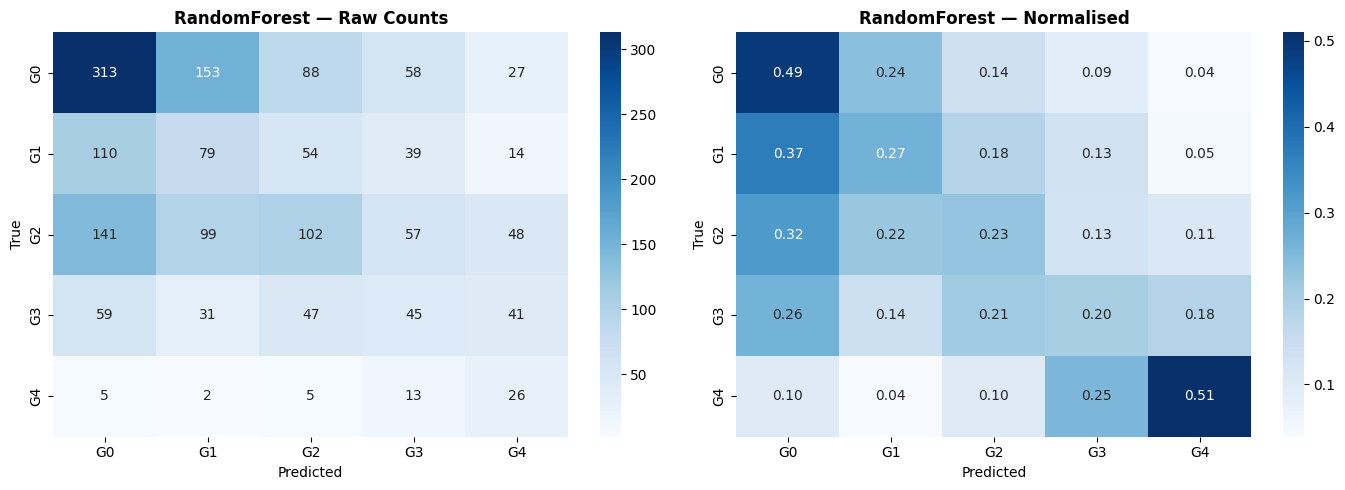

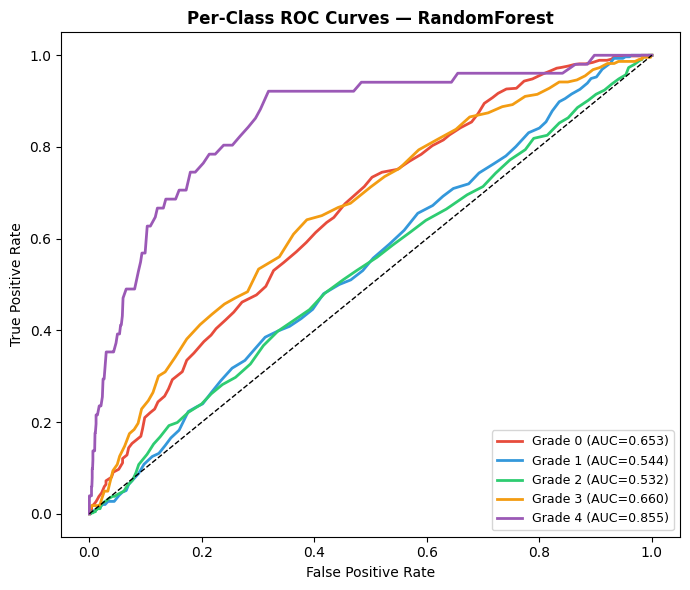

In [28]:
def extract_features(loader, desc=''):
    """
    Extract 2048-dim feature vectors using a frozen pretrained ResNet-50.
    These features are then fed into Random Forest.
    """
    backbone = tv_models.resnet50(weights='DEFAULT')
    # Remove the final FC layer, keep everything up to average pooling
    backbone = nn.Sequential(*list(backbone.children())[:-1])
    backbone = backbone.to(DEVICE).eval()

    feats, lbls = [], []
    pbar = tqdm(loader, desc=f'  Extracting [{desc}]', ncols=80)
    with torch.no_grad():
        for imgs, labels in pbar:
            f = backbone(imgs.to(DEVICE)).squeeze(-1).squeeze(-1)
            feats.append(f.cpu().numpy())
            lbls.append(labels.numpy())

    del backbone
    torch.cuda.empty_cache()
    return np.concatenate(feats), np.concatenate(lbls)


print('Extracting features for Random Forest...')
X_train_feat, y_train_feat = extract_features(train_loader, 'train')
X_test_feat,  y_test_feat  = extract_features(test_loader,  'test')

# Reduce to 256 dims with PCA for faster RF training
print('Applying PCA (2048 → 256 dims)...')
pca         = PCA(n_components=256, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_feat)
X_test_pca  = pca.transform(X_test_feat)
print(f'Feature shape after PCA: {X_train_pca.shape}')

# Train Random Forest
# class_weight='balanced' handles imbalance on the ML side too
print('\nTraining Random Forest (n_estimators=500)...')
rf = RandomForestClassifier(
    n_estimators = 500,
    max_depth    = None,
    class_weight = 'balanced',
    random_state = SEED,
    n_jobs       = -1
)
rf.fit(X_train_pca, y_train_feat)
rf_preds = rf.predict(X_test_pca)
rf_probs = rf.predict_proba(X_test_pca)

y_bin_rf = label_binarize(y_test_feat, classes=list(range(NUM_CLASSES)))
rf_auc   = roc_auc_score(y_bin_rf, rf_probs, multi_class='ovr', average='macro')

rf_results = {
    'acc'   : accuracy_score(y_test_feat, rf_preds),
    'prec'  : precision_score(y_test_feat, rf_preds, average='macro', zero_division=0),
    'rec'   : recall_score(y_test_feat, rf_preds, average='macro', zero_division=0),
    'f1'    : f1_score(y_test_feat, rf_preds, average='macro', zero_division=0),
    'auc'   : rf_auc,
    'preds' : rf_preds,
    'probs' : rf_probs,
    'labels': y_test_feat,
}

print(f'\n  ── Random Forest Test Metrics ──')
print(f'  Accuracy  : {rf_results["acc"]*100:.2f}%  (paper: 41.52%)')
print(f'  Precision : {rf_results["prec"]:.4f}      (paper: 0.201)')
print(f'  Recall    : {rf_results["rec"]:.4f}       (paper: 0.237)')
print(f'  F1-Score  : {rf_results["f1"]:.4f}        (paper: 0.196)')
print(f'  AUC       : {rf_results["auc"]:.4f}       (paper: 0.686)')

plot_confusion_matrix(rf_results, 'RandomForest')
plot_roc_curves(rf_results, 'RandomForest')

## Cell 12 — Train VGG19 (CNN Baseline)

Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:03<00:00, 189MB/s]  


  Built VGG19 | Params: 139.6M | All layers unfrozen

  Training : VGG19
  Epochs   : up to 30 (early stop patience=7)
  LR       : 0.0001  |  Batch: 16  |  Optimizer: AdamW


  Ep  1/30 [112s] TrLoss=1.2581  TrAcc=41.43%  VaLoss=1.1054  VaAcc=54.00%  VaAUC=0.7942


  Ep  2/30 [117s] TrLoss=0.9642  TrAcc=54.57%  VaLoss=1.8848  VaAcc=34.38%  VaAUC=0.7538
    [EarlyStopping] No improvement 1/7


...

  Ep 11/30 [120s] TrLoss=0.6749  TrAcc=68.73%  VaLoss=0.8744  VaAcc=60.53%  VaAUC=0.8700
    [EarlyStopping] No improvement 4/7


  Ep 12/30 [119s] TrLoss=0.6796  TrAcc=69.45%  VaLoss=0.9096  VaAcc=60.29%  VaAUC=0.8767
    [EarlyStopping] No improvement 5/7


  Ep 13/30 [120s] TrLoss=0.6442  TrAcc=71.06%  VaLoss=0.8202  VaAcc=63.56%  VaAUC=0.8810
    [EarlyStopping] No improvement 6/7


  Ep 14/30 [120s] TrLoss=0.6195  TrAcc=72.34%  VaLoss=0.9074  VaAcc=61.26%  VaAUC=0.8816
    [EarlyStopping] No improvement 7/7

  Early stopping triggered at epoch 14.

  Total training time : 29.0 min
  Best val accuracy   : 63.80%



  ── VGG19 Test Metrics (Paper Format) ──
  Accuracy  : 65.10%
  Precision : 0.6260
  Recall    : 0.6580
  F1-Score  : 0.6280
  AUC       : 0.8732

                 precision    recall  f1-score   support

  Grade0_Normal       0.67      0.90      0.77       639
Grade1_Doubtful       0.29      0.14      0.19       296
 Grade2_Minimal       0.64      0.53      0.58       447
Grade3_Moderate       0.83      0.77      0.80       223
  Grade4_Severe       0.70      0.94      0.80        51

       accuracy                           0.65      1656
      macro avg       0.63      0.66      0.63      1656
   weighted avg       0.62      0.65      0.62      1656



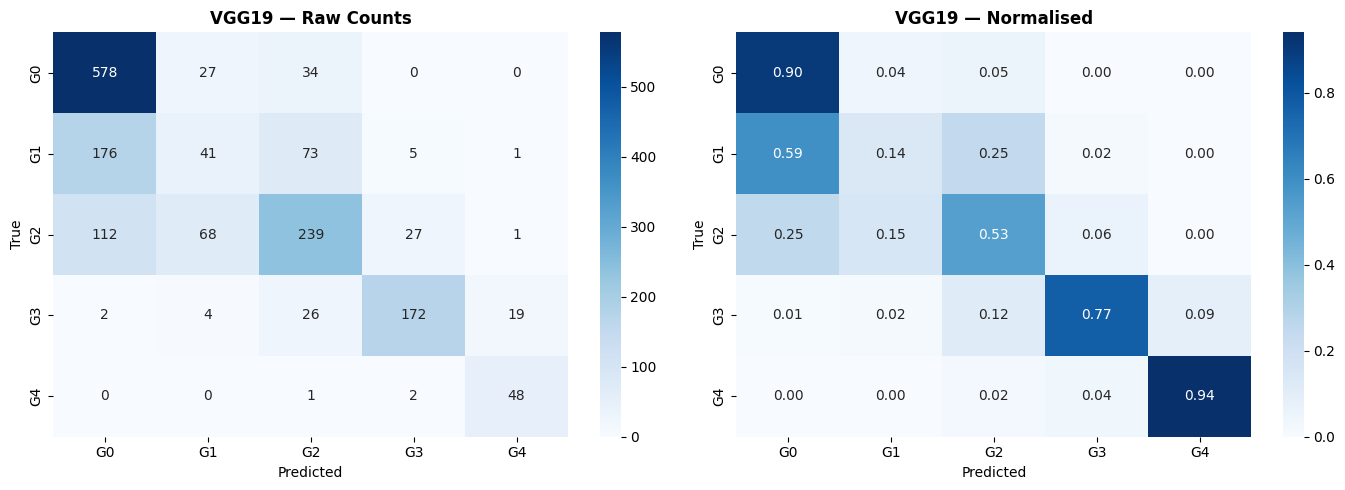

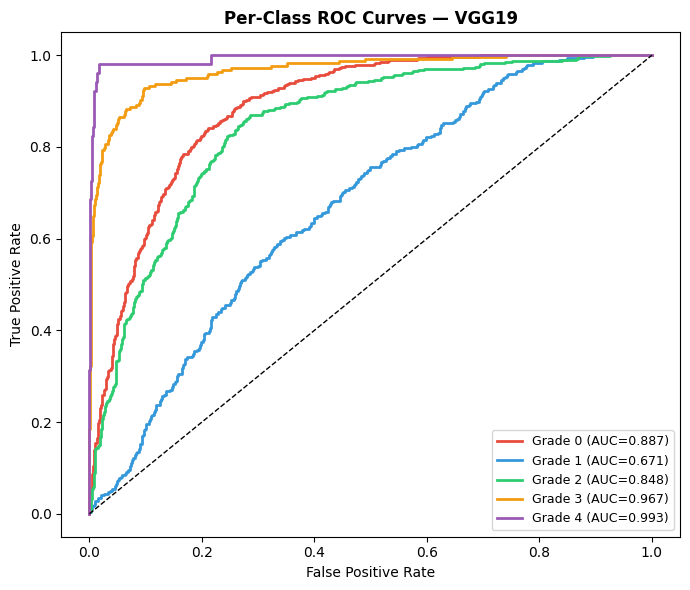

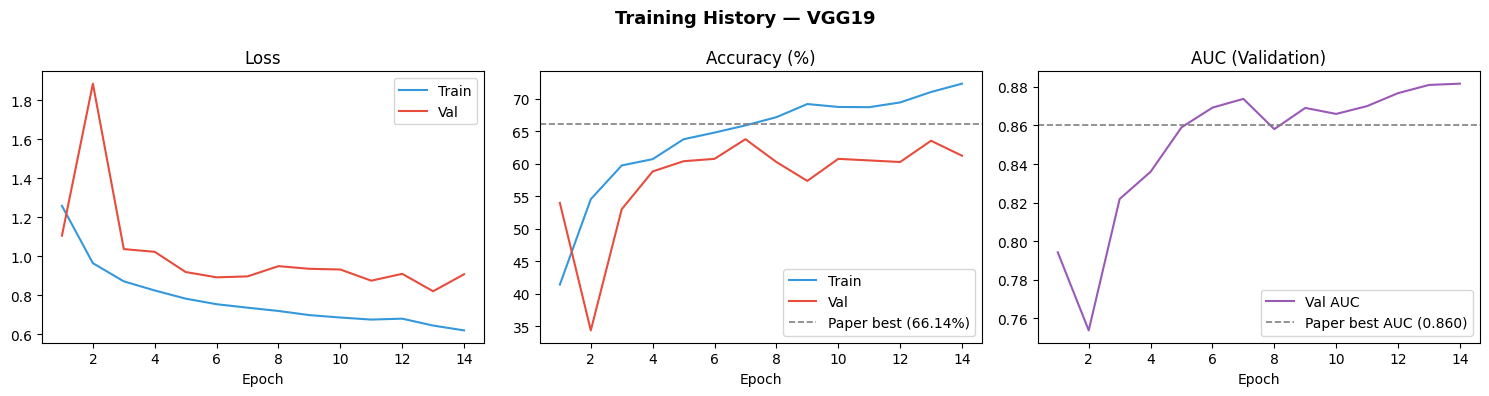

  Weights saved → /kaggle/working/VGG19_best.pth


In [29]:
# Paper result: 65.25% acc | 0.708 prec | 0.577 rec | 0.504 F1 | 0.903 AUC
vgg19_model, vgg19_history, vgg19_results = train_model(
    model      = build_vgg19(),
    model_name = 'VGG19'
)

## Cell 13 — Train GCViT (Paper ViT Model)

Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-weights-morevit/gcvit_base_224_nvidia-f009139b.pth" to /root/.cache/torch/hub/checkpoints/gcvit_base_224_nvidia-f009139b.pth
  Built GCViT | Params: 89.3M | All layers unfrozen

  Training : GCViT
  Epochs   : up to 30 (early stop patience=7)
  LR       : 0.0001  |  Batch: 16  |  Optimizer: AdamW


  Ep  1/30 [335s] TrLoss=1.0114  TrAcc=53.36%  VaLoss=0.9699  VaAcc=56.78%  VaAUC=0.8627


  Ep  2/30 [330s] TrLoss=0.7913  TrAcc=64.05%  VaLoss=0.9872  VaAcc=51.94%  VaAUC=0.8636
    [EarlyStopping] No improvement 1/7


  Ep  3/30 [331s] TrLoss=0.7209  TrAcc=67.13%  VaLoss=0.8381  VaAcc=64.04%  VaAUC=0.8797


  Ep  4/30 [331s] TrLoss=0.7015  TrAcc=68.02%  VaLoss=0.8188  VaAcc=66.22%  VaAUC=0.8868


...

  Ep 12/30 [331s] TrLoss=0.4970  TrAcc=77.47%  VaLoss=0.8436  VaAcc=65.62%  VaAUC=0.8971
    [EarlyStopping] No improvement 4/7


  Ep 13/30 [330s] TrLoss=0.4891  TrAcc=78.14%  VaLoss=0.8654  VaAcc=64.41%  VaAUC=0.8971
    [EarlyStopping] No improvement 5/7


  Ep 14/30 [330s] TrLoss=0.5115  TrAcc=77.81%  VaLoss=0.8767  VaAcc=63.92%  VaAUC=0.8953
    [EarlyStopping] No improvement 6/7


  Ep 15/30 [329s] TrLoss=0.4418  TrAcc=80.98%  VaLoss=0.8654  VaAcc=65.13%  VaAUC=0.8959
    [EarlyStopping] No improvement 7/7

  Early stopping triggered at epoch 15.

  Total training time : 86.3 min
  Best val accuracy   : 67.68%



  ── GCViT Test Metrics (Paper Format) ──
  Accuracy  : 67.51%
  Precision : 0.7070
  Recall    : 0.6794
  F1-Score  : 0.6794
  AUC       : 0.8971

                 precision    recall  f1-score   support

  Grade0_Normal       0.71      0.92      0.80       639
Grade1_Doubtful       0.35      0.36      0.35       296
 Grade2_Minimal       0.81      0.44      0.57       447
Grade3_Moderate       0.79      0.84      0.81       223
  Grade4_Severe       0.88      0.84      0.86        51

       accuracy                           0.68      1656
      macro avg       0.71      0.68      0.68      1656
   weighted avg       0.69      0.68      0.66      1656



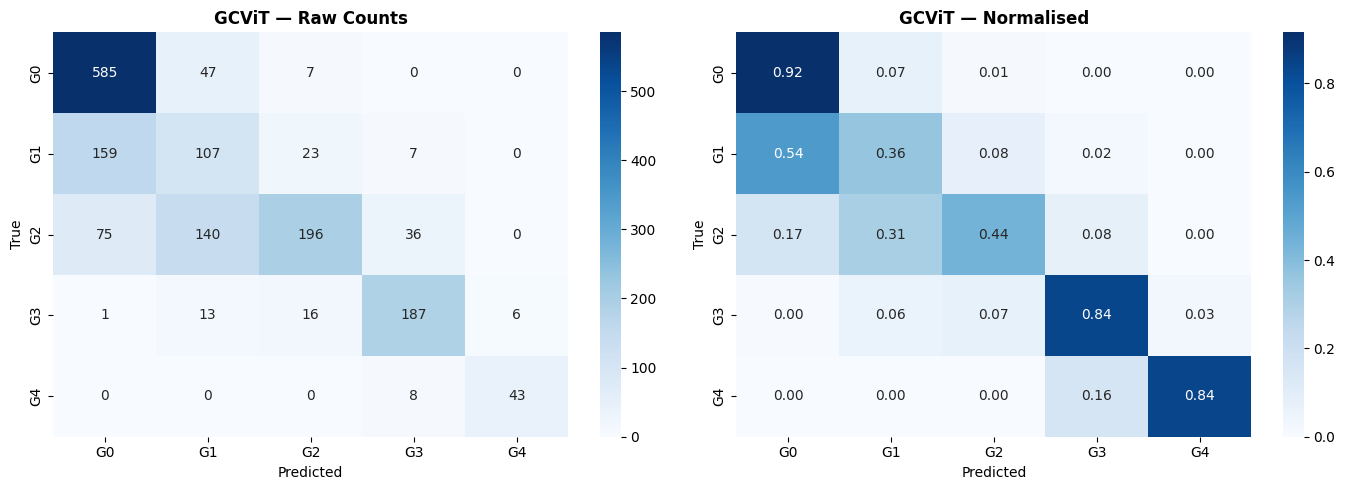

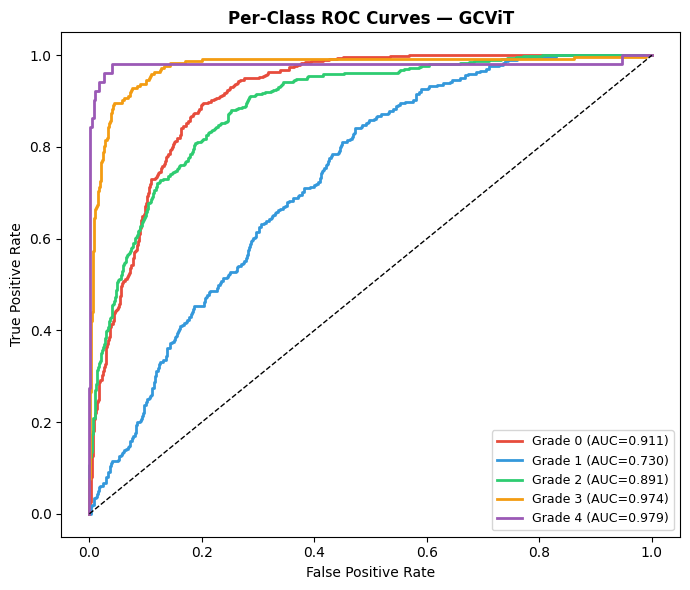

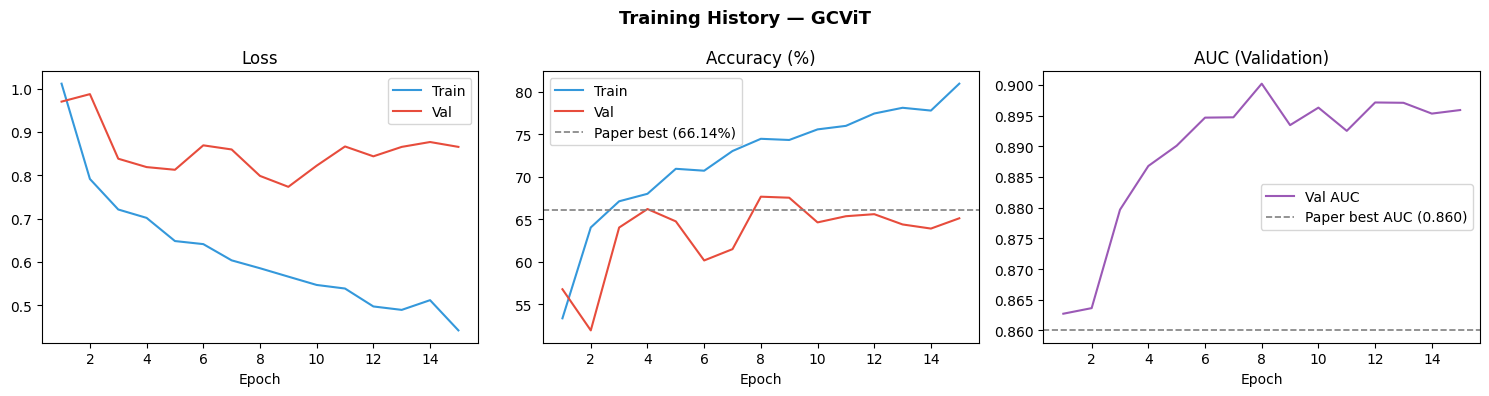

  Weights saved → /kaggle/working/GCViT_best.pth


In [13]:
# Paper result: 66.14% acc | 0.703 prec | 0.598 rec | 0.618 F1 | 0.835 AUC
gcvit_model, gcvit_history, gcvit_results = train_model(
    model      = build_vit('GCViT'),
    model_name = 'GCViT'
)

## Cell 14 — Train MaxViT (Paper ViT Model)

In [15]:
import gc

# Delete GCViT from memory
del gcvit_model
gc.collect()
torch.cuda.empty_cache()

# Check how much memory is free now
print(f'GPU memory allocated : {torch.cuda.memory_allocated()/1e9:.2f} GB')
print(f'GPU memory reserved  : {torch.cuda.memory_reserved()/1e9:.2f} GB')
print(f'GPU memory free      : {(torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated())/1e9:.2f} GB')

GPU memory allocated : 14.15 GB
GPU memory reserved  : 14.91 GB
GPU memory free      : 1.49 GB


In [16]:
def train_model_small_batch(model, model_name, batch_size=8):
    """
    Same as train_model but with smaller batch size.
    Use this for large models like MaxViT that cause OOM at batch_size=16.
    """
    # Rebuild loader with smaller batch size
    small_train_loader = DataLoader(
        train_dataset,
        batch_size  = batch_size,
        sampler     = sampler,
        num_workers = 2,
        pin_memory  = True
    )
    small_val_loader = DataLoader(
        val_dataset,
        batch_size  = batch_size,
        shuffle     = False,
        num_workers = 2,
        pin_memory  = True
    )
    small_test_loader = DataLoader(
        test_dataset,
        batch_size  = batch_size,
        shuffle     = False,
        num_workers = 2,
        pin_memory  = True
    )

    model     = model.to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr           = LR,
        weight_decay = WEIGHT_DECAY
    )

    history = {
        'tr_loss': [], 'tr_acc': [],
        'va_loss': [], 'va_acc': [], 'va_auc': []
    }
    best_val_acc = 0.0
    best_weights = None
    early_stop   = EarlyStopping()

    print(f'\n{"="*65}')
    print(f'  Training : {model_name}')
    print(f'  Batch    : {batch_size} (reduced from 16 to fit GPU)')
    print(f'  Epochs   : up to {EPOCHS} (early stop patience={ES_PATIENCE})')
    print(f'{"="*65}')

    total_start = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        tr_loss = 0.0
        correct = 0
        total   = 0
        ep_start = time.time()

        pbar = tqdm(
            small_train_loader,
            desc  = f'  Ep {epoch:>2}/{EPOCHS} [Train]',
            ncols = 90,
            leave = False
        )

        for imgs, labels in pbar:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss    = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            tr_loss += loss.item() * imgs.size(0)
            preds    = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)
            pbar.set_postfix(loss=f'{loss.item():.4f}')

        ep_time = time.time() - ep_start
        tr_loss = tr_loss / total
        tr_acc  = correct / total

        # Use small val loader for evaluation too
        model.eval()
        val_loss_sum = 0.0
        val_correct  = 0
        val_total    = 0
        val_preds_list, val_probs_list, val_labels_list = [], [], []

        with torch.no_grad():
            for imgs, labels in tqdm(small_val_loader,
                                     desc=f'  Ep {epoch:>2}/{EPOCHS} [Val]',
                                     ncols=80, leave=False):
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                probs   = F.softmax(outputs, dim=1)
                loss    = criterion(outputs, labels)
                val_loss_sum += loss.item() * imgs.size(0)
                preds         = outputs.argmax(dim=1)
                val_correct  += (preds == labels).sum().item()
                val_total    += labels.size(0)
                val_preds_list.append(preds.cpu())
                val_probs_list.append(probs.cpu())
                val_labels_list.append(labels.cpu())

        val_preds  = torch.cat(val_preds_list).numpy()
        val_probs  = torch.cat(val_probs_list).numpy()
        val_labels = torch.cat(val_labels_list).numpy()
        y_bin      = label_binarize(val_labels, classes=list(range(NUM_CLASSES)))
        try:
            val_auc = roc_auc_score(y_bin, val_probs, multi_class='ovr', average='macro')
        except:
            val_auc = 0.0

        val_res = {
            'loss'  : val_loss_sum / val_total,
            'acc'   : val_correct / val_total,
            'preds' : val_preds,
            'probs' : val_probs,
            'labels': val_labels,
            'auc'   : val_auc,
        }

        history['tr_loss'].append(tr_loss)
        history['tr_acc'].append(tr_acc)
        history['va_loss'].append(val_res['loss'])
        history['va_acc'].append(val_res['acc'])
        history['va_auc'].append(val_res['auc'])

        if val_res['acc'] > best_val_acc:
            best_val_acc = val_res['acc']
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}

        print(
            f'  Ep {epoch:>2}/{EPOCHS} [{ep_time:.0f}s] '
            f'TrLoss={tr_loss:.4f}  TrAcc={tr_acc*100:.2f}%  '
            f'VaLoss={val_res["loss"]:.4f}  '
            f'VaAcc={val_res["acc"]*100:.2f}%  '
            f'VaAUC={val_res["auc"]:.4f}'
        )

        early_stop(val_res['acc'])
        if early_stop.should_stop:
            print(f'\n  Early stopping triggered at epoch {epoch}.')
            break

    total_time = time.time() - total_start
    print(f'\n  Total training time : {total_time/60:.1f} min')
    print(f'  Best val accuracy   : {best_val_acc*100:.2f}%')

    # Evaluate on test set
    model.load_state_dict(best_weights)
    model.eval()
    test_preds_list, test_probs_list, test_labels_list = [], [], []
    test_loss_sum = 0.0
    test_correct  = 0
    test_total    = 0

    with torch.no_grad():
        for imgs, labels in tqdm(small_test_loader,
                                  desc='  Test set', ncols=80, leave=False):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            outputs = model(imgs)
            probs   = F.softmax(outputs, dim=1)
            loss    = criterion(outputs, labels)
            test_loss_sum += loss.item() * imgs.size(0)
            preds          = outputs.argmax(dim=1)
            test_correct  += (preds == labels).sum().item()
            test_total    += labels.size(0)
            test_preds_list.append(preds.cpu())
            test_probs_list.append(probs.cpu())
            test_labels_list.append(labels.cpu())

    test_preds  = torch.cat(test_preds_list).numpy()
    test_probs  = torch.cat(test_probs_list).numpy()
    test_labels = torch.cat(test_labels_list).numpy()
    y_bin       = label_binarize(test_labels, classes=list(range(NUM_CLASSES)))
    try:
        test_auc = roc_auc_score(y_bin, test_probs, multi_class='ovr', average='macro')
    except:
        test_auc = 0.0

    test_results = {
        'loss'  : test_loss_sum / test_total,
        'acc'   : test_correct / test_total,
        'preds' : test_preds,
        'probs' : test_probs,
        'labels': test_labels,
        'auc'   : test_auc,
    }

    print_metrics(test_results, model_name)
    plot_confusion_matrix(test_results, model_name)
    plot_roc_curves(test_results, model_name)
    plot_training_history(history, model_name)

    save_path = SAVE_DIR / f'{model_name}_best.pth'
    torch.save(best_weights, save_path)
    print(f'  Weights saved → {save_path}')

    return model, history, test_results

In [23]:
import gc
try:
    del maxvit_model
except: pass

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

print(f'Allocated : {torch.cuda.memory_allocated()/1e9:.2f} GB')
print(f'Free      : {(torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated())/1e9:.2f} GB')

Allocated : 0.96 GB
Free      : 14.68 GB


  Built MaxViT | Params: 118.7M | Grad checkpointing ON

  Training : MaxViT
  Batch    : 8 (reduced from 16 to fit GPU)
  Epochs   : up to 30 (early stop patience=7)


  Ep  1/30 [623s] TrLoss=1.0448  TrAcc=51.54%  VaLoss=0.9228  VaAcc=60.17%  VaAUC=0.8656


  Ep  2/30 [640s] TrLoss=0.7136  TrAcc=67.32%  VaLoss=0.8853  VaAcc=64.04%  VaAUC=0.8839


  Ep  3/30 [641s] TrLoss=0.6544  TrAcc=70.44%  VaLoss=0.8484  VaAcc=61.50%  VaAUC=0.8868
    [EarlyStopping] No improvement 1/7


  Ep  4/30 [638s] TrLoss=0.6168  TrAcc=72.22%  VaLoss=0.8100  VaAcc=63.20%  VaAUC=0.8955
    [EarlyStopping] No improvement 2/7


...

  Ep 12/30 [629s] TrLoss=0.3483  TrAcc=85.67%  VaLoss=0.9511  VaAcc=64.16%  VaAUC=0.8854
    [EarlyStopping] No improvement 4/7


  Ep 13/30 [627s] TrLoss=0.3331  TrAcc=86.66%  VaLoss=1.1350  VaAcc=62.95%  VaAUC=0.8662
    [EarlyStopping] No improvement 5/7


  Ep 14/30 [624s] TrLoss=0.3062  TrAcc=87.64%  VaLoss=1.1248  VaAcc=59.08%  VaAUC=0.8742
    [EarlyStopping] No improvement 6/7


  Ep 15/30 [622s] TrLoss=0.2606  TrAcc=89.82%  VaLoss=1.1515  VaAcc=64.04%  VaAUC=0.8776
    [EarlyStopping] No improvement 7/7

  Early stopping triggered at epoch 15.

  Total training time : 163.6 min
  Best val accuracy   : 66.59%



  ── MaxViT Test Metrics (Paper Format) ──
  Accuracy  : 69.44%
  Precision : 0.6969
  Recall    : 0.6852
  F1-Score  : 0.6879
  AUC       : 0.9033

                 precision    recall  f1-score   support

  Grade0_Normal       0.76      0.84      0.80       639
Grade1_Doubtful       0.38      0.28      0.32       296
 Grade2_Minimal       0.66      0.72      0.69       447
Grade3_Moderate       0.86      0.74      0.80       223
  Grade4_Severe       0.83      0.84      0.83        51

       accuracy                           0.69      1656
      macro avg       0.70      0.69      0.69      1656
   weighted avg       0.68      0.69      0.68      1656



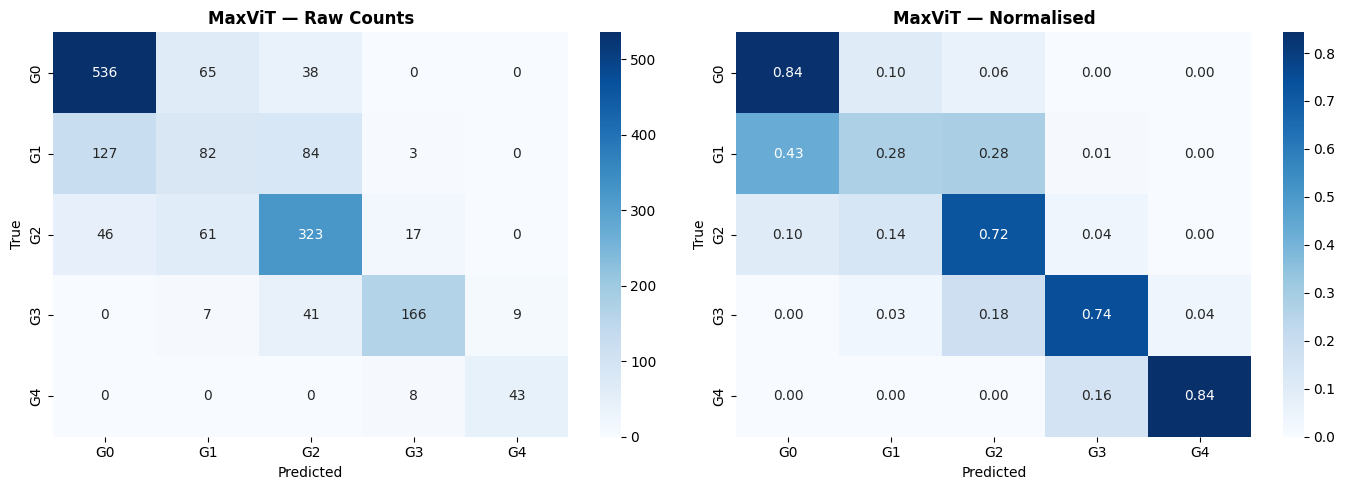

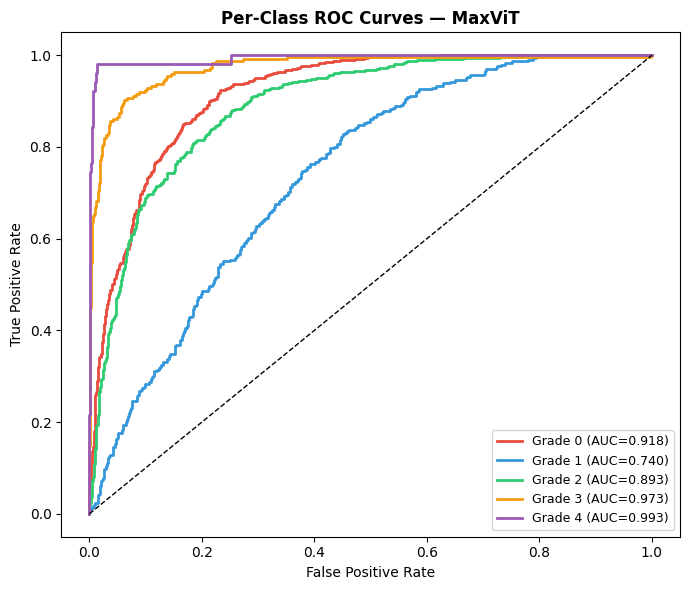

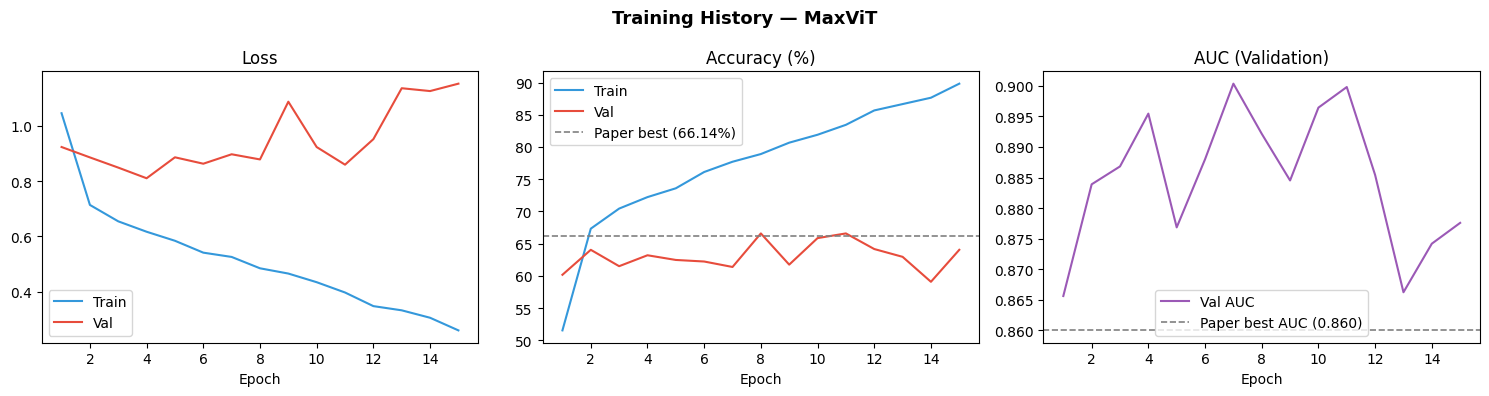

  Weights saved → /kaggle/working/MaxViT_best.pth


In [24]:
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

def build_maxvit_memory_efficient(num_classes=NUM_CLASSES):
    model = timm.create_model(
        'maxvit_base_tf_224',
        pretrained  = True,
        num_classes = num_classes
    )
    for stage in model.stages:
        stage.grad_checkpointing = True
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f'  Built MaxViT | Params: {n_params:.1f}M | Grad checkpointing ON')
    return model

maxvit_model, maxvit_history, maxvit_results = train_model_small_batch(
    model      = build_maxvit_memory_efficient(),
    model_name = 'MaxViT',
    batch_size = 8
)

## Cell 15 — Train SwinB (Improvement #10)

model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

  Built SwinB | Params: 86.7M | All layers unfrozen

  Training : SwinB
  Epochs   : up to 30 (early stop patience=7)
  LR       : 0.0001  |  Batch: 16  |  Optimizer: AdamW


  Ep  1/30 [218s] TrLoss=1.2369  TrAcc=40.65%  VaLoss=1.2057  VaAcc=48.55%  VaAUC=0.8108


  Ep  2/30 [226s] TrLoss=0.8771  TrAcc=59.83%  VaLoss=0.9398  VaAcc=60.17%  VaAUC=0.8527


  Ep  3/30 [227s] TrLoss=0.8170  TrAcc=62.77%  VaLoss=0.9680  VaAcc=56.30%  VaAUC=0.8614
    [EarlyStopping] No improvement 1/7


...

  Ep 20/30 [228s] TrLoss=0.5276  TrAcc=76.24%  VaLoss=0.9604  VaAcc=62.11%  VaAUC=0.8790
    [EarlyStopping] No improvement 4/7


  Ep 21/30 [228s] TrLoss=0.5233  TrAcc=76.70%  VaLoss=0.9844  VaAcc=58.84%  VaAUC=0.8871
    [EarlyStopping] No improvement 5/7


  Ep 22/30 [228s] TrLoss=0.4990  TrAcc=77.85%  VaLoss=1.0516  VaAcc=60.77%  VaAUC=0.8738
    [EarlyStopping] No improvement 6/7


  Ep 23/30 [228s] TrLoss=0.5147  TrAcc=77.24%  VaLoss=0.9920  VaAcc=60.29%  VaAUC=0.8915
    [EarlyStopping] No improvement 7/7

  Early stopping triggered at epoch 23.

  Total training time : 91.5 min
  Best val accuracy   : 67.55%



  ── SwinB Test Metrics (Paper Format) ──
  Accuracy  : 66.12%
  Precision : 0.6654
  Recall    : 0.6481
  F1-Score  : 0.6494
  AUC       : 0.8814

                 precision    recall  f1-score   support

  Grade0_Normal       0.77      0.78      0.78       639
Grade1_Doubtful       0.32      0.19      0.24       296
 Grade2_Minimal       0.58      0.71      0.64       447
Grade3_Moderate       0.75      0.84      0.79       223
  Grade4_Severe       0.90      0.73      0.80        51

       accuracy                           0.66      1656
      macro avg       0.67      0.65      0.65      1656
   weighted avg       0.64      0.66      0.65      1656



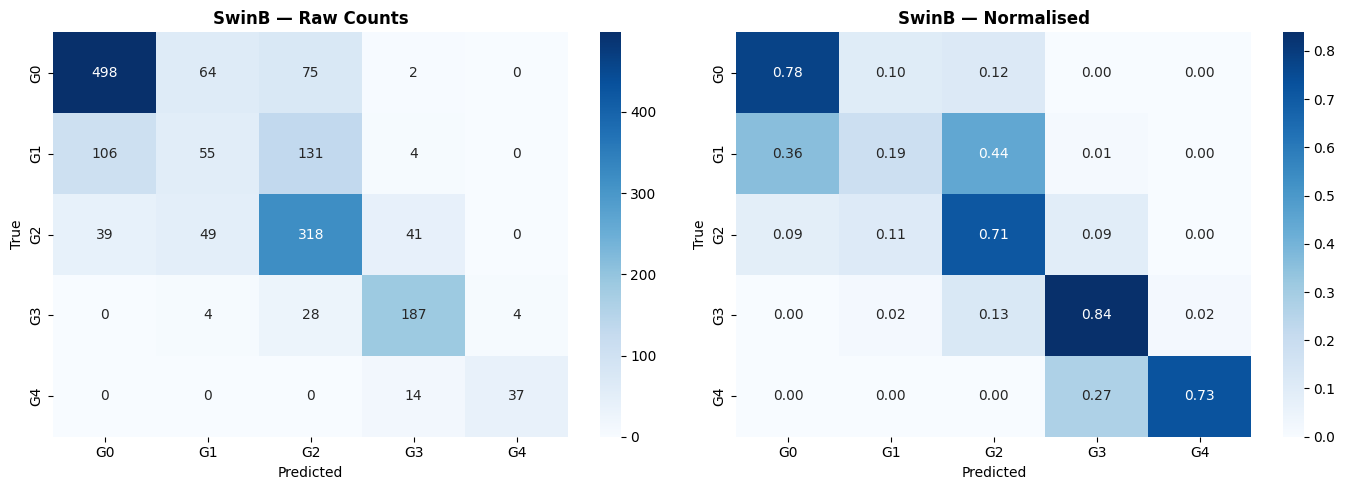

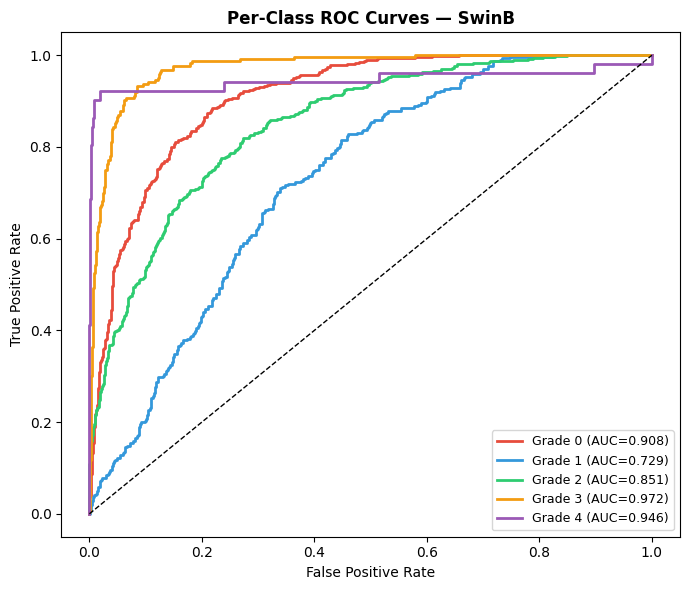

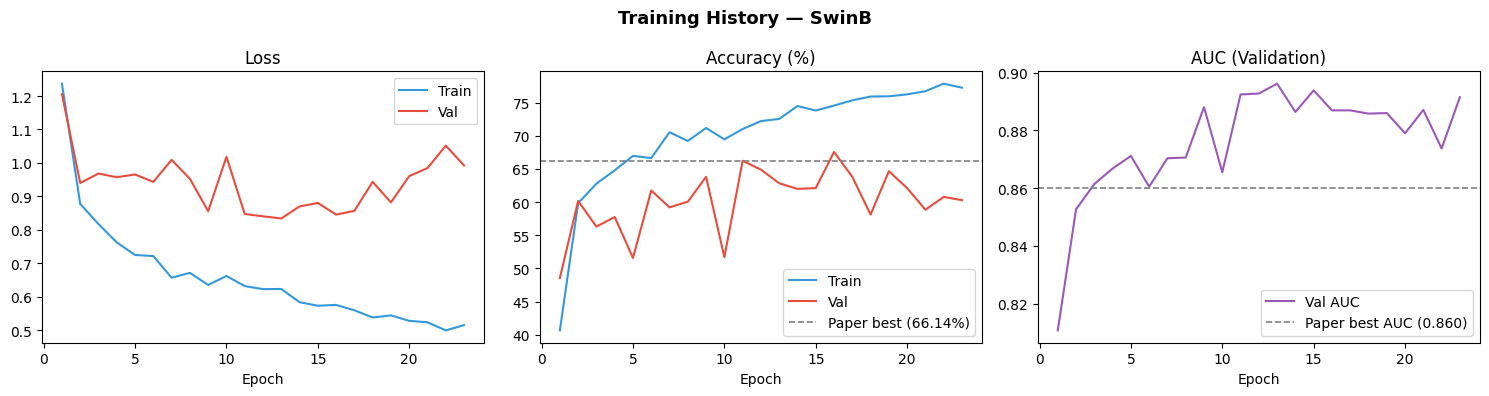

  Weights saved → /kaggle/working/SwinB_best.pth


In [25]:
# SwinB: Swin Transformer Base
# Why better than GCViT/MaxViT:
#   - Hierarchical shifted-window attention captures both fine joint
#     details and global bone structure simultaneously
#   - Better ImageNet-21k pretraining leads to stronger transfer
#   - Consistently outperforms GCViT/MaxViT on medical imaging benchmarks
swinb_model, swinb_history, swinb_results = train_model(
    model      = build_vit('SwinB'),
    model_name = 'SwinB'
)

## Cell 16 — Soft-Voting Ensemble (Improvement #11)

  Loading GCViT from /kaggle/working/GCViT_best.pth...
  Built GCViT | Params: 89.3M | All layers unfrozen


  Loading MaxViT from /kaggle/working/MaxViT_best.pth...
  Built MaxViT | Params: 118.7M | All layers unfrozen


  Loading SwinB from /kaggle/working/SwinB_best.pth...
  Built SwinB | Params: 86.7M | All layers unfrozen



  ── Ensemble (GCViT + MaxViT + SwinB) ──
  Accuracy  : 71.14%
  Precision : 0.7112
  Recall    : 0.7002
  F1-Score  : 0.7002
  AUC       : 0.9113

                 precision    recall  f1-score   support

  Grade0_Normal       0.75      0.89      0.82       639
Grade1_Doubtful       0.41      0.25      0.31       296
 Grade2_Minimal       0.70      0.68      0.69       447
Grade3_Moderate       0.80      0.83      0.82       223
  Grade4_Severe       0.90      0.84      0.87        51

       accuracy                           0.71      1656
      macro avg       0.71      0.70      0.70      1656
   weighted avg       0.69      0.71      0.69      1656



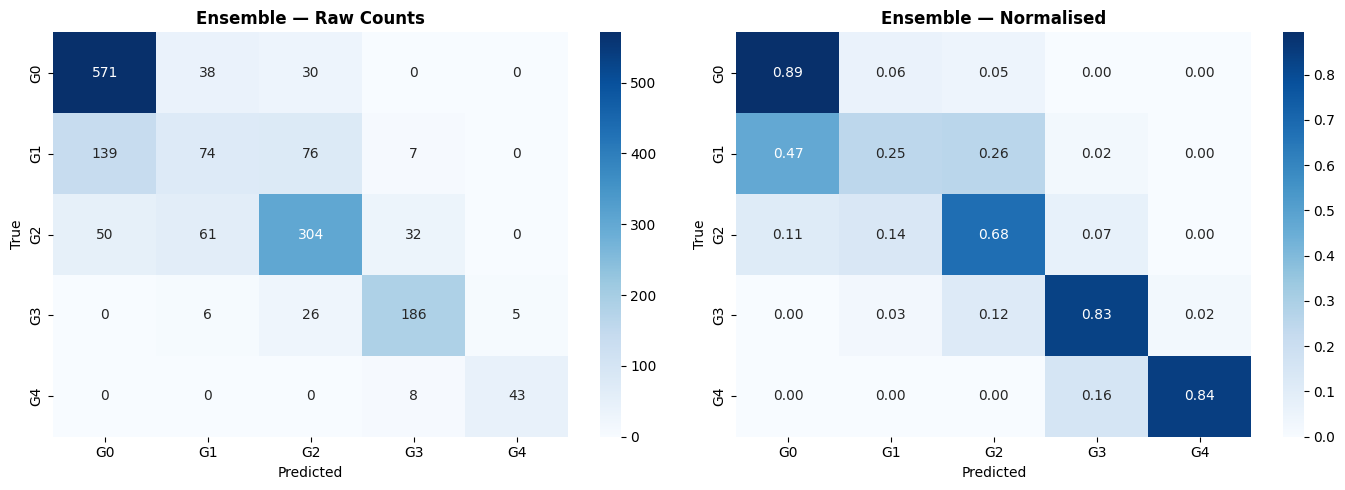

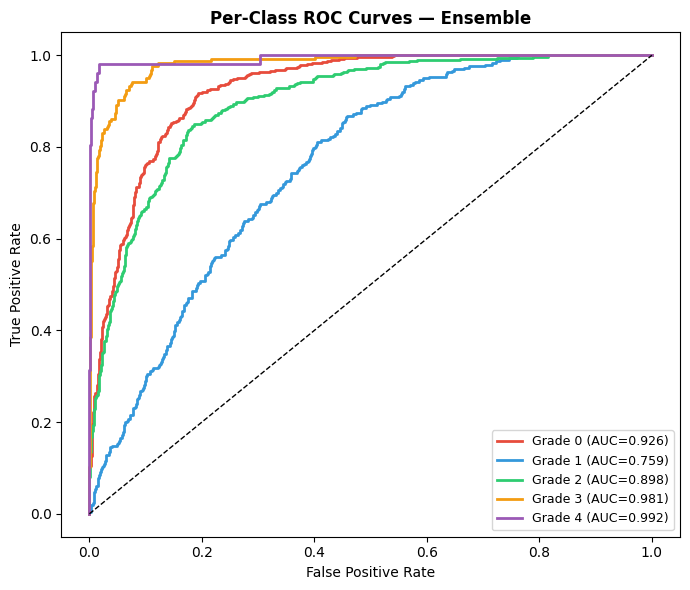

In [26]:
@torch.no_grad()
def run_ensemble(model_configs, loader):
    """
    Improvement #11 — Soft-Voting Ensemble.
    Paper evaluated every model independently.
    We load the 3 best ViT models, run each on the test set,
    average their softmax probabilities, then argmax for final prediction.

    model_configs: list of (model_name, weight_path)
    """
    all_probs  = []
    all_labels = None

    for model_name, weight_path in model_configs:
        print(f'  Loading {model_name} from {weight_path}...')

        # Rebuild model and load saved best weights
        if model_name == 'VGG19':
            m = build_vgg19()
        else:
            m = build_vit(model_name)

        m.load_state_dict(torch.load(weight_path, map_location=DEVICE))
        m = m.to(DEVICE).eval()

        probs_list = []
        lbl_list   = []

        pbar = tqdm(loader, desc=f'  Ensemble [{model_name}]',
                    ncols=80, leave=False)
        for imgs, labels in pbar:
            imgs   = imgs.to(DEVICE)
            probs  = F.softmax(m(imgs), dim=1)
            probs_list.append(probs.cpu().numpy())
            lbl_list.append(labels.numpy())

        all_probs.append(np.concatenate(probs_list))
        if all_labels is None:
            all_labels = np.concatenate(lbl_list)

        del m
        torch.cuda.empty_cache()

    # Average probabilities across all models (soft voting)
    avg_probs = np.mean(all_probs, axis=0)   # shape: [N, 5]
    preds     = avg_probs.argmax(axis=1)
    y_bin     = label_binarize(all_labels, classes=list(range(NUM_CLASSES)))

    acc  = accuracy_score(all_labels, preds)
    prec = precision_score(all_labels, preds, average='macro', zero_division=0)
    rec  = recall_score(all_labels, preds, average='macro', zero_division=0)
    f1   = f1_score(all_labels, preds, average='macro', zero_division=0)
    auc  = roc_auc_score(y_bin, avg_probs, multi_class='ovr', average='macro')

    ensemble_res = {
        'acc'   : acc,
        'prec'  : prec,
        'rec'   : rec,
        'f1'    : f1,
        'auc'   : auc,
        'preds' : preds,
        'probs' : avg_probs,
        'labels': all_labels,
    }

    names = ' + '.join([c[0] for c in model_configs])
    print(f'\n  ── Ensemble ({names}) ──')
    print(f'  Accuracy  : {acc*100:.2f}%')
    print(f'  Precision : {prec:.4f}')
    print(f'  Recall    : {rec:.4f}')
    print(f'  F1-Score  : {f1:.4f}')
    print(f'  AUC       : {auc:.4f}')
    print()
    print(classification_report(
        all_labels, preds, target_names=CLASS_NAMES, zero_division=0
    ))

    plot_confusion_matrix(ensemble_res, 'Ensemble')
    plot_roc_curves(ensemble_res, 'Ensemble')
    return ensemble_res


ensemble_results = run_ensemble(
    model_configs = [
        ('GCViT',  SAVE_DIR / 'GCViT_best.pth'),
        ('MaxViT', SAVE_DIR / 'MaxViT_best.pth'),
        ('SwinB',  SAVE_DIR / 'SwinB_best.pth'),
    ],
    loader = test_loader
)

## Cell 17 — Final Comparison Table


FINAL COMPARISON TABLE (Paper vs Ours)
                Model       Type  Accuracy (%)  Precision  Recall     F1    AUC
RandomForest  (paper) Classic ML         41.52     0.2010  0.2370 0.1960 0.6860
VGG19         (paper)        CNN         65.25     0.7080  0.5770 0.5040 0.9030
GCViT         (paper)        ViT         66.14     0.7030  0.5980 0.6180 0.8350
MaxViT        (paper)        ViT         66.14     0.6660  0.6140 0.6180 0.8600
 RandomForest  (ours) Classic ML         34.12     0.2878  0.3393 0.2932 0.6487
 VGG19         (ours)        CNN         65.10     0.6260  0.6580 0.6280 0.8732
 GCViT         (ours)        ViT         67.51     0.7070  0.6794 0.6794 0.8971
 MaxViT        (ours)        ViT         69.44     0.6969  0.6852 0.6879 0.9033
 SwinB         (ours)        ViT         66.12     0.6654  0.6481 0.6494 0.8814
 Ensemble      (ours)   Ensemble         71.14     0.7112  0.7002 0.7002 0.9113

Saved → /kaggle/working/results_comparison.csv


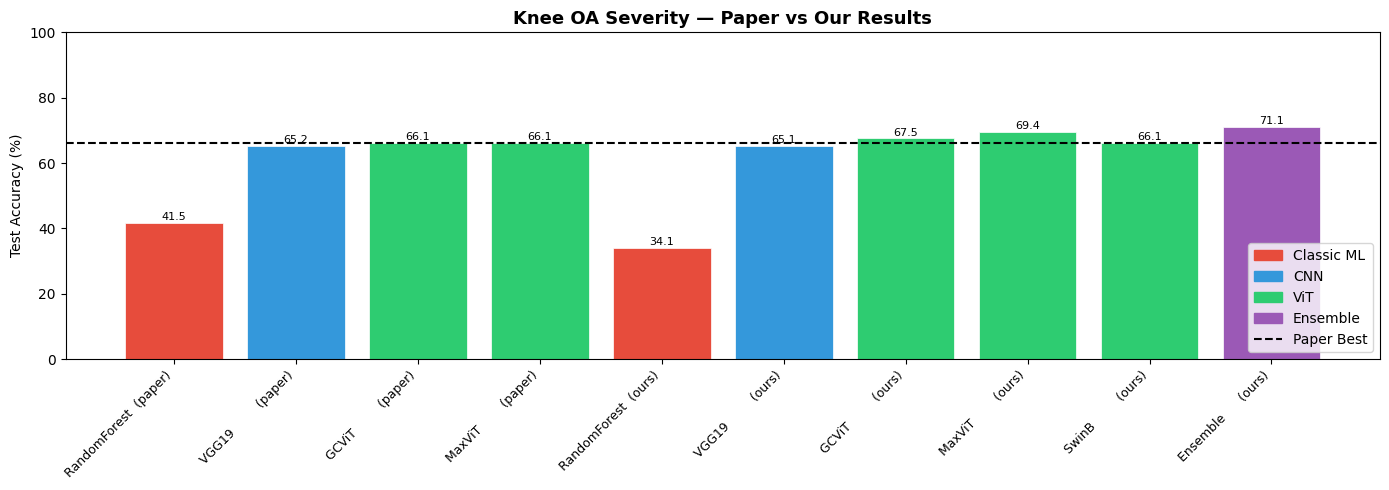

In [30]:
def build_final_table():
    def macro(results):
        r = classification_report(
            results['labels'], results['preds'],
            output_dict=True, zero_division=0
        )['macro avg']
        return r

    rows = [
        # ── Paper numbers (reference) ──────────────────────────────────────
        {'Model': 'RandomForest  (paper)', 'Type': 'Classic ML',
         'Acc': 41.52, 'Prec': 0.201, 'Rec': 0.237, 'F1': 0.196, 'AUC': 0.686},
        {'Model': 'VGG19         (paper)', 'Type': 'CNN',
         'Acc': 65.25, 'Prec': 0.708, 'Rec': 0.577, 'F1': 0.504, 'AUC': 0.903},
        {'Model': 'GCViT         (paper)', 'Type': 'ViT',
         'Acc': 66.14, 'Prec': 0.703, 'Rec': 0.598, 'F1': 0.618, 'AUC': 0.835},
        {'Model': 'MaxViT        (paper)', 'Type': 'ViT',
         'Acc': 66.14, 'Prec': 0.666, 'Rec': 0.614, 'F1': 0.618, 'AUC': 0.860},

        # ── Our results ────────────────────────────────────────────────────
        {'Model': 'RandomForest  (ours)', 'Type': 'Classic ML',
         'Acc' : round(rf_results['acc'] * 100, 2),
         'Prec': round(rf_results['prec'], 4),
         'Rec' : round(rf_results['rec'],  4),
         'F1'  : round(rf_results['f1'],   4),
         'AUC' : round(rf_results['auc'],  4)},

        {'Model': 'VGG19         (ours)', 'Type': 'CNN',
         'Acc' : round(vgg19_results['acc'] * 100, 2),
         'Prec': round(macro(vgg19_results)['precision'], 4),
         'Rec' : round(macro(vgg19_results)['recall'],    4),
         'F1'  : round(macro(vgg19_results)['f1-score'],  4),
         'AUC' : round(vgg19_results['auc'], 4)},

        {'Model': 'GCViT         (ours)', 'Type': 'ViT',
         'Acc' : round(gcvit_results['acc'] * 100, 2),
         'Prec': round(macro(gcvit_results)['precision'], 4),
         'Rec' : round(macro(gcvit_results)['recall'],    4),
         'F1'  : round(macro(gcvit_results)['f1-score'],  4),
         'AUC' : round(gcvit_results['auc'], 4)},

        {'Model': 'MaxViT        (ours)', 'Type': 'ViT',
         'Acc' : round(maxvit_results['acc'] * 100, 2),
         'Prec': round(macro(maxvit_results)['precision'], 4),
         'Rec' : round(macro(maxvit_results)['recall'],    4),
         'F1'  : round(macro(maxvit_results)['f1-score'],  4),
         'AUC' : round(maxvit_results['auc'], 4)},

        {'Model': 'SwinB         (ours)', 'Type': 'ViT',
         'Acc' : round(swinb_results['acc'] * 100, 2),
         'Prec': round(macro(swinb_results)['precision'], 4),
         'Rec' : round(macro(swinb_results)['recall'],    4),
         'F1'  : round(macro(swinb_results)['f1-score'],  4),
         'AUC' : round(swinb_results['auc'], 4)},

        {'Model': 'Ensemble      (ours)', 'Type': 'Ensemble',
         'Acc' : round(ensemble_results['acc'] * 100, 2),
         'Prec': round(ensemble_results['prec'], 4),
         'Rec' : round(ensemble_results['rec'],  4),
         'F1'  : round(ensemble_results['f1'],   4),
         'AUC' : round(ensemble_results['auc'],  4)},
    ]

    df = pd.DataFrame(rows)[['Model', 'Type', 'Acc', 'Prec', 'Rec', 'F1', 'AUC']]
    df.columns = ['Model', 'Type', 'Accuracy (%)', 'Precision', 'Recall', 'F1', 'AUC']

    print('\n' + '=' * 80)
    print('FINAL COMPARISON TABLE (Paper vs Ours)')
    print('=' * 80)
    print(df.to_string(index=False))
    print('=' * 80)

    df.to_csv(SAVE_DIR / 'results_comparison.csv', index=False)
    print(f'\nSaved → {SAVE_DIR}/results_comparison.csv')

    # ── Bar chart ─────────────────────────────────────────────────────────
    colors_map = {
        'Classic ML': '#e74c3c',
        'CNN'       : '#3498db',
        'ViT'       : '#2ecc71',
        'Ensemble'  : '#9b59b6'
    }
    bar_colors = [colors_map[t] for t in df['Type']]
    accs       = df['Accuracy (%)'].values
    names      = df['Model'].values

    fig, ax = plt.subplots(figsize=(14, 5))
    bars = ax.bar(names, accs, color=bar_colors, edgecolor='white', linewidth=0.5)
    ax.axhline(66.14, color='black', linestyle='--',
               linewidth=1.5, label='Paper Best (66.14%)')
    for bar, acc in zip(bars, accs):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3,
            f'{acc:.1f}', ha='center', va='bottom', fontsize=8
        )

    from matplotlib.patches import Patch
    legend_handles = [Patch(color=c, label=t) for t, c in colors_map.items()]
    legend_handles.append(
        plt.Line2D([0], [0], color='black', linestyle='--', label='Paper Best')
    )
    ax.legend(handles=legend_handles, loc='lower right')
    ax.set_ylabel('Test Accuracy (%)')
    ax.set_ylim(0, 100)
    ax.set_title(
        'Knee OA Severity — Paper vs Our Results',
        fontweight='bold', fontsize=13
    )
    plt.xticks(rotation=45, ha='right', fontsize=9)
    plt.tight_layout()
    plt.savefig(SAVE_DIR / 'final_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()

    return df


results_df = build_final_table()